<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_LAB_PRACTICALS/blob/main/Regression_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Harshini Ramdas Bhandary

PRN : 202401040151

ROLL no : 35

Division : A

Title : Performance Evaluation of Regression Model on House price prediction

Aim : To develop a Linear Regression model for real-world house price prediction using Gradient Descent optimization and evaluate its performance using appropriate regression metrics.

Objectives :
1. To analyze a real-world house price dataset and understand the relationship between property-related features and house prices.
2. To preprocess the dataset by checking missing values, selecting relevant features, splitting the data into training and testing sets, and applying feature scaling.
3. To implement Linear Regression using Gradient Descent from scratch and understand the process of parameter optimization.
4. To study the effect of different learning rates and numbers of iterations on the convergence and performance of Gradient Descent.
5. To evaluate the model using MAE, MSE, RMSE, and R² Score to measure prediction performance.
6. To compare the Gradient Descent implementation with Scikit-learn's Linear Regression model and analyze their performance.
7. To visualize model behavior and results using convergence, actual-vs-predicted, residual, and experimental analysis graphs.
8. To analyze the limitations and practical considerations of using Linear Regression and Gradient Descent for house price prediction.

Flowchart :

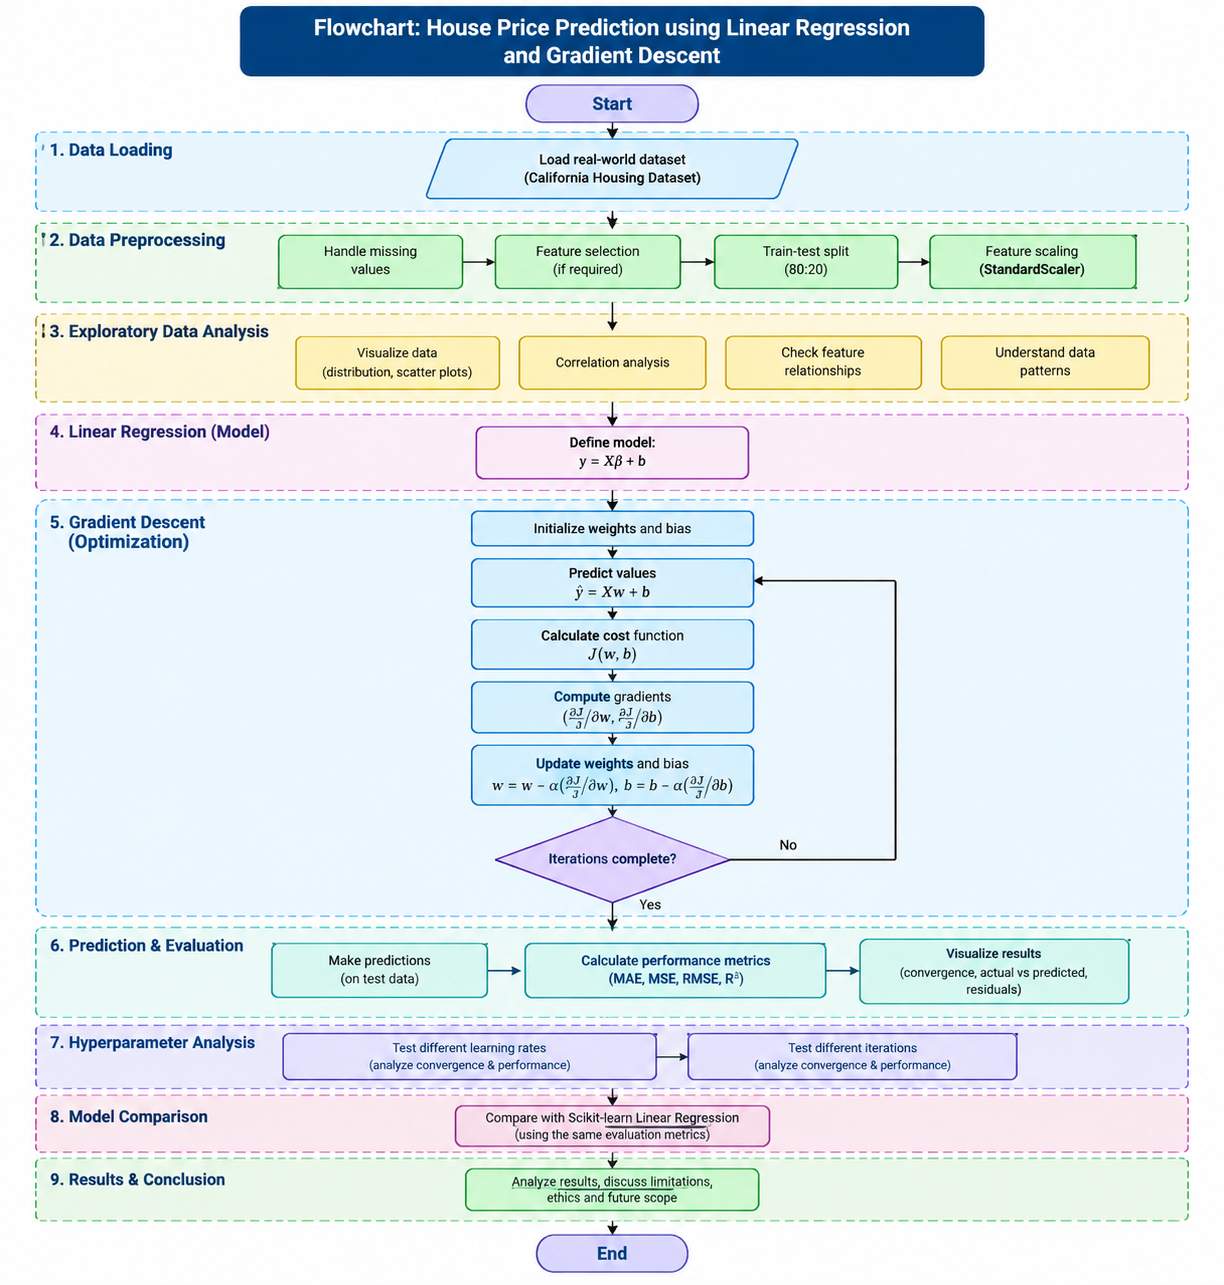


Note: this notebook builds the same house price model in two ways. First with Gradient Descent written by hand with NumPy, and then with scikit-learn. We also write the metrics and the normal equation by hand, and check that every version gives nearly the same answer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def show(frame, digits=4):
    # prints a dataframe as simple lines of text, one line for each row
    for name, row in frame.iterrows():
        parts = []
        for col, val in row.items():
            parts.append(f"{col} = {val:.{digits}f}" if isinstance(val, (float, np.floating)) else f"{col} = {val}")
        print(f"{name}:  " + ",  ".join(parts))

print("Libraries loaded.")

Libraries loaded.


## 1. Loading the house price data

In [2]:
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name="HousePrice")      # price in units of 100,000 dollars

print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:", X.columns.tolist())
print("Missing values in total:", int(X.isnull().sum().sum()))
print()
print("A summary of every feature:")
show(X.describe().T[["mean", "std", "min", "max"]], digits=2)

Number of rows: 20640
Number of features: 8
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Missing values in total: 0

A summary of every feature:
MedInc:  mean = 3.87,  std = 1.90,  min = 0.50,  max = 15.00
HouseAge:  mean = 28.64,  std = 12.59,  min = 1.00,  max = 52.00
AveRooms:  mean = 5.43,  std = 2.47,  min = 0.85,  max = 141.91
AveBedrms:  mean = 1.10,  std = 0.47,  min = 0.33,  max = 34.07
Population:  mean = 1425.48,  std = 1132.46,  min = 3.00,  max = 35682.00
AveOccup:  mean = 3.07,  std = 10.39,  min = 0.69,  max = 1243.33
Latitude:  mean = 35.63,  std = 2.14,  min = 32.54,  max = 41.95
Longitude:  mean = -119.57,  std = 2.00,  min = -124.35,  max = -114.31


## 2. A first look at the data

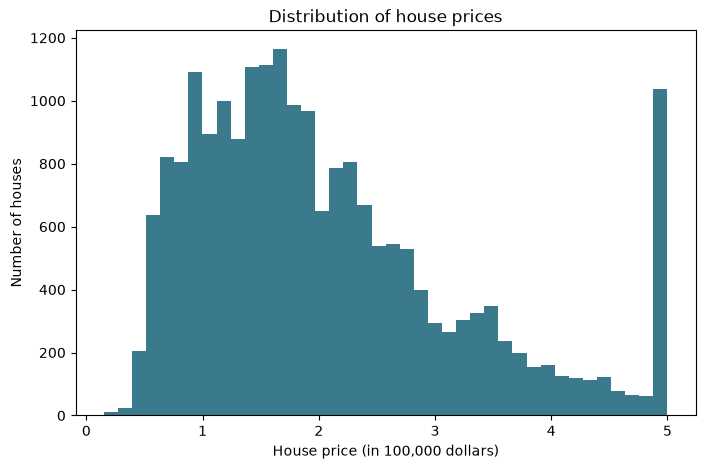

How each feature moves with the house price:
   MedInc: 0.6881
   AveRooms: 0.1519
   HouseAge: 0.1056
   AveOccup: -0.0237
   Population: -0.0246
   Longitude: -0.0460
   AveBedrms: -0.0467
   Latitude: -0.1442


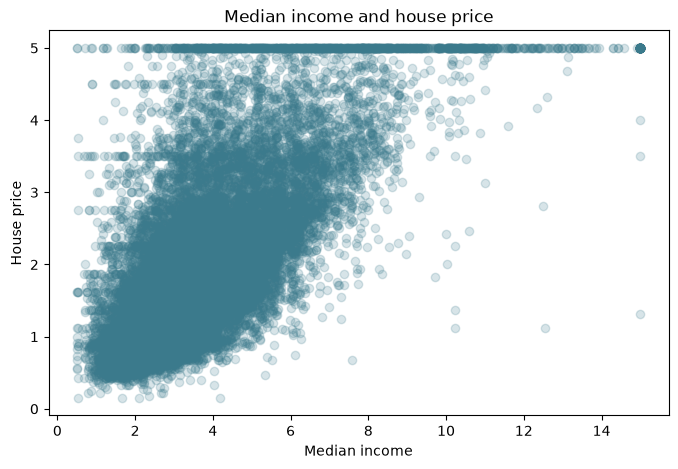

In [3]:
plt.figure(figsize=(8, 5))
plt.hist(y, bins=40, color="#3b7a8c")
plt.xlabel("House price (in 100,000 dollars)")
plt.ylabel("Number of houses")
plt.title("Distribution of house prices")
plt.show()

corr = pd.concat([X, y], axis=1).corr()["HousePrice"].drop("HousePrice").sort_values(ascending=False)
print("How each feature moves with the house price:")
for name, val in corr.items():
    print(f"   {name}: {val:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X["MedInc"], y, alpha=0.2, color="#3b7a8c")
plt.xlabel("Median income")
plt.ylabel("House price")
plt.title("Median income and house price")
plt.show()

## 3. Train and test split, and feature scaling

We keep 80 percent of the houses for training and 20 percent for testing. Gradient Descent works well only when all the features are on a similar range, so we scale them. Scaling is done with a formula, (value - mean) / spread, using the numbers of the training houses only. We do it by hand and also with StandardScaler, and check that both give the same numbers.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training houses:", len(X_train))
print("Testing houses:", len(X_test))

# scaling written by hand
mean_tr = X_train.values.mean(axis=0)
spread_tr = X_train.values.std(axis=0)
X_train_scaled = (X_train.values - mean_tr) / spread_tr
X_test_scaled = (X_test.values - mean_tr) / spread_tr

# the same thing with the library
scaler = StandardScaler()
X_train_lib = scaler.fit_transform(X_train)
X_test_lib = scaler.transform(X_test)

print("Biggest difference between hand scaling and StandardScaler:",
      max(np.abs(X_train_scaled - X_train_lib).max(), np.abs(X_test_scaled - X_test_lib).max()))

Training houses: 16512
Testing houses: 4128
Biggest difference between hand scaling and StandardScaler: 0.0


## 4. Scores written by hand

We write the four scores ourselves, so that we know exactly what they measure.
* MAE: the average size of the mistakes.
* MSE: the average of the squared mistakes.
* RMSE: the square root of MSE, which is in the same unit as the price.
* R2 score: the share of the ups and downs in price that the model explains. 1 is perfect and 0 is no better than always guessing the average.

In [5]:
def my_mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))

def my_mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))

def my_rmse(y_true, y_pred):
    return float(np.sqrt(my_mse(y_true, y_pred)))

def my_r2(y_true, y_pred):
    left_over = np.sum((y_true - y_pred) ** 2)
    total = np.sum((y_true - y_true.mean()) ** 2)
    return float(1 - left_over / total)

def my_scores(y_true, y_pred):
    return {"MAE": my_mae(y_true, y_pred), "MSE": my_mse(y_true, y_pred),
            "RMSE": my_rmse(y_true, y_pred), "R2": my_r2(y_true, y_pred)}

def library_scores(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": float(np.sqrt(mse)), "R2": float(r2_score(y_true, y_pred))}

# quick check with a made up example
a = np.array([3.0, 2.5, 4.0, 5.5]); b = np.array([2.8, 2.9, 3.5, 6.0])
print("Ours        :", {k: round(v, 6) for k, v in my_scores(a, b).items()})
print("scikit-learn:", {k: round(v, 6) for k, v in library_scores(a, b).items()})

Ours        : {'MAE': 0.4, 'MSE': 0.175, 'RMSE': 0.41833, 'R2': 0.866667}
scikit-learn: {'MAE': 0.4, 'MSE': 0.175, 'RMSE': 0.41833, 'R2': 0.866667}


## 5. Linear Regression with Gradient Descent (from scratch)

Gradient Descent starts with all weights at zero. In every step it works out the error of the predictions, finds the slope of the cost for each weight, and moves the weights a small step downhill. The size of the step is the learning rate.

In [6]:
def gradient_descent(X, y, learning_rate, iterations):
    m = len(y)
    weights = np.zeros(X.shape[1])
    bias = 0
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X, weights) + bias
        error = predictions - y
        cost = np.mean(error ** 2) / 2
        cost_history.append(cost)

        dw = np.dot(X.T, error) / m
        db = np.sum(error) / m

        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db

    return weights, bias, cost_history

learning_rate = 0.01
iterations = 1000
weights, bias, cost_history = gradient_descent(X_train_scaled, y_train.values, learning_rate, iterations)
y_pred_gd = np.dot(X_test_scaled, weights) + bias

print("Training finished.")
print("Test scores of Gradient Descent:", {k: round(v, 4) for k, v in my_scores(y_test.values, y_pred_gd).items()})

Training finished.
Test scores of Gradient Descent: {'MAE': 0.5477, 'MSE': 0.5672, 'RMSE': 0.7531, 'R2': 0.5672}


## 6. The same model with the exact formula and with scikit-learn

Linear regression also has an exact answer, the normal equation. After moving every column to a mean of zero, the weights are

w = (X^T X)^-1 X^T y

and the bias is the mean of y minus the mean of x times w. We write this by hand, and we also train the scikit-learn LinearRegression. All three should give nearly the same weights.

In [7]:
def normal_equation(X, y):
    x_mean, y_mean = X.mean(axis=0), y.mean()
    Xc, yc = X - x_mean, y - y_mean
    w = np.linalg.solve(Xc.T @ Xc, Xc.T @ yc)
    b = y_mean - x_mean @ w
    return w, b

w_exact, b_exact = normal_equation(X_train_scaled, y_train.values)
y_pred_exact = X_test_scaled @ w_exact + b_exact

model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred_sklearn = model.predict(X_test_scaled)

print("Scores on the test houses")
print("   Gradient Descent (ours) :", {k: round(v, 4) for k, v in my_scores(y_test.values, y_pred_gd).items()})
print("   Normal equation (ours)  :", {k: round(v, 4) for k, v in my_scores(y_test.values, y_pred_exact).items()})
print("   scikit-learn            :", {k: round(v, 4) for k, v in library_scores(y_test.values, y_pred_sklearn).items()})
print()
print("Check of our scores against the library scores on the same predictions:")
print("   ours        :", {k: round(v, 6) for k, v in my_scores(y_test.values, y_pred_sklearn).items()})
print("   scikit-learn:", {k: round(v, 6) for k, v in library_scores(y_test.values, y_pred_sklearn).items()})
print()
print("Biggest weight difference, normal equation and scikit-learn:", np.abs(w_exact - model.coef_).max())
print("Biggest weight difference, Gradient Descent and scikit-learn:", np.abs(weights - model.coef_).max().round(4))

Scores on the test houses
   Gradient Descent (ours) : {'MAE': 0.5477, 'MSE': 0.5672, 'RMSE': 0.7531, 'R2': 0.5672}
   Normal equation (ours)  : {'MAE': 0.5332, 'MSE': 0.5559, 'RMSE': 0.7456, 'R2': 0.5758}
   scikit-learn            : {'MAE': 0.5332, 'MSE': 0.5559, 'RMSE': 0.7456, 'R2': 0.5758}

Check of our scores against the library scores on the same predictions:
   ours        : {'MAE': 0.5332, 'MSE': 0.555892, 'RMSE': 0.745581, 'R2': 0.575788}
   scikit-learn: {'MAE': 0.5332, 'MSE': 0.555892, 'RMSE': 0.745581, 'R2': 0.575788}

Biggest weight difference, normal equation and scikit-learn: 4.218847493575595e-15
Biggest weight difference, Gradient Descent and scikit-learn: 0.4184


## 7. Graphs of the Gradient Descent model

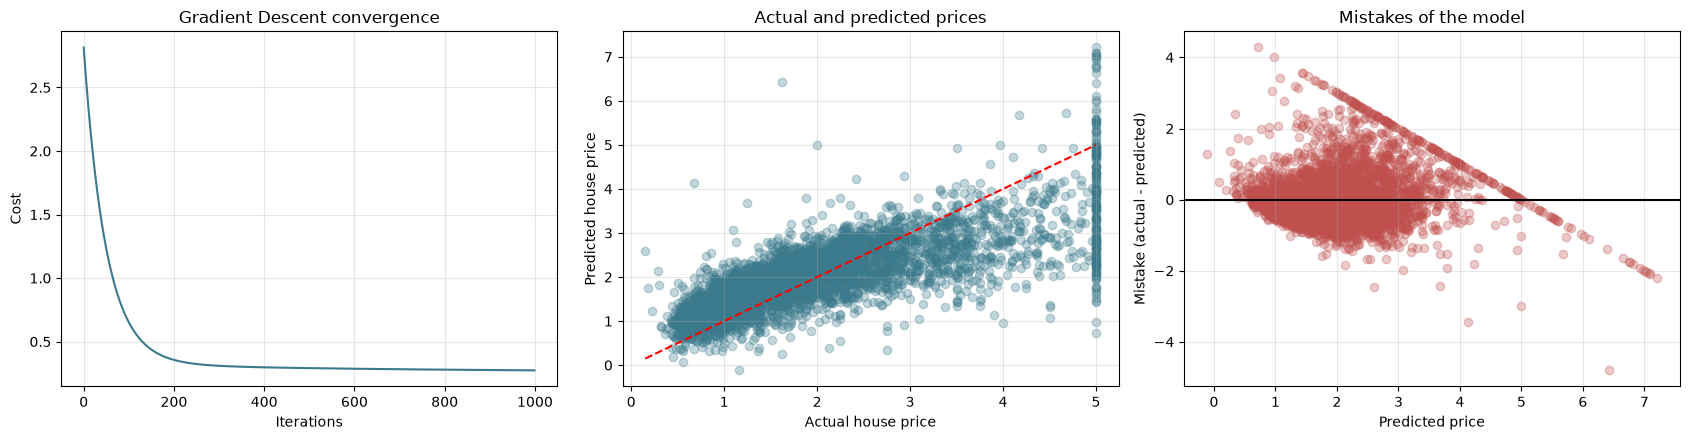

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(cost_history, color="#3b7a8c")
ax[0].set_xlabel("Iterations"); ax[0].set_ylabel("Cost"); ax[0].set_title("Gradient Descent convergence"); ax[0].grid(alpha=0.3)

ax[1].scatter(y_test, y_pred_gd, alpha=0.3, color="#3b7a8c")
lims = [y_test.min(), y_test.max()]
ax[1].plot(lims, lims, "r--")
ax[1].set_xlabel("Actual house price"); ax[1].set_ylabel("Predicted house price"); ax[1].set_title("Actual and predicted prices"); ax[1].grid(alpha=0.3)

residuals = y_test.values - y_pred_gd
ax[2].scatter(y_pred_gd, residuals, alpha=0.3, color="#c0504d"); ax[2].axhline(0, color="k")
ax[2].set_xlabel("Predicted price"); ax[2].set_ylabel("Mistake (actual - predicted)"); ax[2].set_title("Mistakes of the model"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Effect of the learning rate and the number of iterations

First we keep 1000 iterations and change the learning rate. Then we keep the learning rate at 0.01 and change the number of iterations.

Different learning rates (1000 iterations):
0.0001:  Final cost = 2.3613,  MAE = 1.8597,  MSE = 4.6437
0.001:  Final cost = 0.6557,  MAE = 0.8191,  MSE = 1.3025
0.01:  Final cost = 0.2739,  MAE = 0.5477,  MSE = 0.5672
0.05:  Final cost = 0.2590,  MAE = 0.5329,  MSE = 0.5562

Different numbers of iterations (learning rate 0.01):
100:  Final cost = 0.6588,  MAE = 0.8166,  MSE = 1.2966
500:  Final cost = 0.2915,  MAE = 0.5652,  MSE = 0.5961
1000:  Final cost = 0.2739,  MAE = 0.5477,  MSE = 0.5672
2000:  Final cost = 0.2623,  MAE = 0.5352,  MSE = 0.5546
5000:  Final cost = 0.2590,  MAE = 0.5329,  MSE = 0.5562


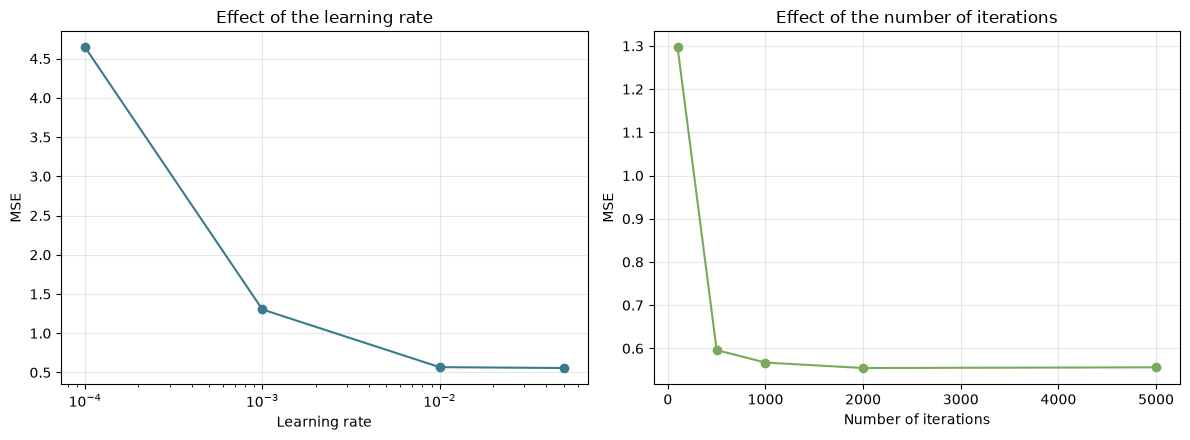

In [9]:
lr_rows = []
for lr in [0.0001, 0.001, 0.01, 0.05]:
    w_t, b_t, cost_t = gradient_descent(X_train_scaled, y_train.values, lr, 1000)
    s = my_scores(y_test.values, X_test_scaled @ w_t + b_t)
    lr_rows.append({"Learning rate": lr, "Final cost": cost_t[-1], "MAE": s["MAE"], "MSE": s["MSE"]})
lr_table = pd.DataFrame(lr_rows)

it_rows = []
for it in [100, 500, 1000, 2000, 5000]:
    w_t, b_t, cost_t = gradient_descent(X_train_scaled, y_train.values, 0.01, it)
    s = my_scores(y_test.values, X_test_scaled @ w_t + b_t)
    it_rows.append({"Iterations": it, "Final cost": cost_t[-1], "MAE": s["MAE"], "MSE": s["MSE"]})
it_table = pd.DataFrame(it_rows)

print("Different learning rates (1000 iterations):")
show(lr_table.set_index("Learning rate"))
print()
print("Different numbers of iterations (learning rate 0.01):")
show(it_table.set_index("Iterations"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(lr_table["Learning rate"], lr_table["MSE"], "o-", color="#3b7a8c")
ax[0].set_xscale("log"); ax[0].set_xlabel("Learning rate"); ax[0].set_ylabel("MSE"); ax[0].set_title("Effect of the learning rate"); ax[0].grid(alpha=0.3)
ax[1].plot(it_table["Iterations"], it_table["MSE"], "o-", color="#7aa95c")
ax[1].set_xlabel("Number of iterations"); ax[1].set_ylabel("MSE"); ax[1].set_title("Effect of the number of iterations"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Weights and sample predictions

In [10]:
print("Weights of every feature (on the scaled data):")
for i, name in enumerate(X.columns):
    print(f"   {name}: Gradient Descent {weights[i]:.4f},  normal equation {w_exact[i]:.4f},  scikit-learn {model.coef_[i]:.4f}")
print(f"   bias: Gradient Descent {bias:.4f},  normal equation {b_exact:.4f},  scikit-learn {model.intercept_:.4f}")

print()
print("First 10 test houses (price in 100,000 dollars):")
for k in range(10):
    print(f"   actual {y_test.values[k]:.3f},  Gradient Descent {y_pred_gd[k]:.3f},  scikit-learn {y_pred_sklearn[k]:.3f}")

Weights of every feature (on the scaled data):
   MedInc: Gradient Descent 0.8289,  normal equation 0.8544,  scikit-learn 0.8544
   HouseAge: Gradient Descent 0.1785,  normal equation 0.1225,  scikit-learn 0.1225
   AveRooms: Gradient Descent -0.1379,  normal equation -0.2944,  scikit-learn -0.2944
   AveBedrms: Gradient Descent 0.1567,  normal equation 0.3393,  scikit-learn 0.3393
   Population: Gradient Descent 0.0168,  normal equation -0.0023,  scikit-learn -0.0023
   AveOccup: Gradient Descent -0.0452,  normal equation -0.0408,  scikit-learn -0.0408
   Latitude: Gradient Descent -0.4871,  normal equation -0.8969,  scikit-learn -0.8969
   Longitude: Gradient Descent -0.4515,  normal equation -0.8698,  scikit-learn -0.8698
   bias: Gradient Descent 2.0719,  normal equation 2.0719,  scikit-learn 2.0719

First 10 test houses (price in 100,000 dollars):
   actual 0.477,  Gradient Descent 0.881,  scikit-learn 0.719
   actual 0.458,  Gradient Descent 1.653,  scikit-learn 1.764
   actual 5

Results

We built a house price model on the California housing data and trained it in three ways: Gradient Descent written by hand, the normal equation written by hand, and the scikit-learn LinearRegression. The scores were also written by hand and they matched the scikit-learn scores to six decimal places.

Scores on the 4128 test houses (price is in units of 100,000 dollars):
* Gradient Descent (1000 iterations, learning rate 0.01): MAE 0.5477, MSE 0.5672, RMSE 0.7531, R2 0.5672
* Normal equation: MAE 0.5332, MSE 0.5559, RMSE 0.7456, R2 0.5758
* scikit-learn LinearRegression: MAE 0.5332, MSE 0.5559, RMSE 0.7456, R2 0.5758

The normal equation and scikit-learn gave the same weights (the difference is smaller than 0.000000000001). Gradient Descent after 1000 steps is close but not exactly there, and its weights for Latitude and Longitude are still about 0.4 away from the exact ones. These two features move together, so Gradient Descent needs more steps for them. With 5000 iterations the test MSE (0.5562) is almost the same as the exact answer (0.5559).

Learning rate: with 1000 iterations the test MSE was 4.64 for a rate of 0.0001, 1.30 for 0.001, 0.5672 for 0.01 and 0.5562 for 0.05. So a very small rate learns too slowly, and a rate around 0.01 to 0.05 works well here.

Iterations: with a rate of 0.01 the test MSE was 1.30 after 100 iterations, 0.596 after 500, 0.567 after 1000 and 0.5546 after 2000. After that the change is tiny, so the model has almost reached the bottom.

Outcomes

1. A house price prediction model was built with Linear Regression on real data.
2. Gradient Descent was written from scratch and checked against the exact formula and scikit-learn.
3. MAE, MSE, RMSE and R2 were written by hand and checked against scikit-learn.
4. The need for feature scaling was shown, and the hand-made scaling matched StandardScaler.
5. The effect of the learning rate and of the number of iterations was studied.
6. Graphs of convergence, actual against predicted prices and the mistakes of the model were studied.

Conclusion

Linear Regression with Gradient Descent gives almost the same prices as the library model when the learning rate and the number of steps are chosen well. A very small learning rate is too slow, and too few iterations stop the learning early. The R2 score of about 0.57 tells us that a straight line explains a little more than half of the changes in house price. Prices depend on the location in a way that is not a straight line, and the prices in this data stop at 5.0, so the model is weak for the most expensive houses. A model that can bend, such as a tree based model, or extra location features, would probably do better.